# Phase 1 · Task 1.4 – 1.5 (UCI HAR)
Baseline 학습(Mamba / 1D CNN / LSTM) → Mamba block tensor shape 추적. (Task 1.5의 LTI 검증·학습, Δ 분석은 별도 노트북.)

- 공식 test는 로드하지 않는다. split은 starter 기본값(`split_seed=42`, `val_fraction=0.2`, **subject 단위**) → Task 1.1–1.3과 같은 validation 피험자.
- 학습 설정(모든 모델 동일, starter 기본값): 20 epochs, batch 64, AdamW lr 1e-3, d_model 32, 2 layers (Mamba: d_state 16, expand 2, d_conv 4). seed 0/1/2, seed마다 **validation macro-F1 최고 epoch** 선택, std는 sample std(ddof=1).

## 0. Setup & 데이터

In [1]:
import sys, json, inspect
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.nn import functional as F

ROOT = Path.cwd() if (Path.cwd() / "mamba_starter").is_dir() else Path.cwd().parent
STARTER = ROOT / "mamba_starter"
sys.path.insert(0, str(STARTER))
from data import load_har, subject_split, Standardizer, HAR_CLASSES
from models import build_model
from train import make_loader, evaluate_model
import mamba_block, models
torch.set_num_threads(4)                                                        # 공유 서버: CPU thread 과점 방지

# 학습은 mamba_starter/ 에서 starter train.py로 수행 (공유 GPU 포화로 CPU 사용, 데이터 없으면 --download 추가):
#   python train.py --dataset har --data_root data/har --model {mamba,cnn,lstm} --seeds 0 1 2 --device cpu --out runs/har_{model}
RUNS = STARTER / "runs"
MODELS = {"mamba": "Mamba (selective)", "cnn": "1D CNN", "lstm": "LSTM"}
FIG = ROOT / "outputs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RESULTS = {}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.fontsize": 8})
MODEL_COLORS = {"mamba": "tab:red", "cnn": "tab:blue", "lstm": "tab:green"}
SHORT = ["WALK", "UP", "DOWN", "SIT", "STAND", "LAY"]

In [2]:
summ = {m: json.loads((RUNS / f"har_{m}" / "summary.json").read_text()) for m in MODELS}
split = {m: json.loads((RUNS / f"har_{m}" / "split.json").read_text()) for m in MODELS}
assert all(split[m] == split["mamba"] for m in MODELS)                          # 세 모델 같은 split
assert all([r["seed"] for r in summ[m]["runs"]] == [0, 1, 2] for m in MODELS)

x_all, y_all, subj_all = load_har(STARTER / "data" / "har")                     # 공식 TRAIN만: [7352,128,9]
tr, va = subject_split(subj_all, val_fraction=0.2, split_seed=42)
print("train subjects:", split["mamba"]["train_subjects"])
print("val   subjects:", split["mamba"]["val_subjects"])
pd.DataFrame({"train": np.bincount(y_all[tr], minlength=6), "val": np.bincount(y_all[va], minlength=6)}, index=HAR_CLASSES)

train subjects: [1, 3, 5, 6, 7, 8, 11, 14, 15, 16, 19, 22, 23, 27, 28, 29]
val   subjects: [17, 21, 25, 26, 30]


,train,val
WALKING,915,311
WALKING_UPSTAIRS,793,280
WALKING_DOWNSTAIRS,725,261
SITTING,932,354
STANDING,1000,374
LAYING,1027,380


## Task 1.4 · Baseline training
`runs/har_{mamba,cnn,lstm}/summary.json`(seed별 best epoch의 validation 지표)을 집계. confusion matrix는 행 = 정답, 열 = 예측.

In [3]:
rows = []
for m, name in MODELS.items():
    s = summ[m]
    rows.append({"model": name, "params": s["runs"][0]["parameters"],
                 "val_acc": f"{s['accuracy']['mean']:.4f} ± {s['accuracy']['std']:.4f}",
                 "val_macro_F1": f"{s['macro_f1']['mean']:.4f} ± {s['macro_f1']['std']:.4f}",
                 **{f"F1 seed{r['seed']}": round(r["macro_f1"], 4) for r in s["runs"]},
                 "best_epoch": [r["epoch"] for r in s["runs"]]})
main_table = pd.DataFrame(rows).set_index("model")
RESULTS["task1_4"] = {m: {"params": summ[m]["runs"][0]["parameters"], "accuracy": summ[m]["accuracy"],
                          "macro_f1": summ[m]["macro_f1"], "runs": summ[m]["runs"]} for m in MODELS}
main_table

,params,val_acc,val_macro_F1,F1 seed0,F1 seed1,F1 seed2,best_epoch
model,,,,,,,
Mamba (selective),20454,0.9507 ± 0.0041,0.9548 ± 0.0041,0.9531,0.9519,0.9595,"[13, 11, 15]"
1D CNN,6822,0.9252 ± 0.0120,0.9298 ± 0.0121,0.9437,0.9217,0.9240,"[20, 10, 16]"
LSTM,14150,0.9276 ± 0.0172,0.9312 ± 0.0172,0.9265,0.9168,0.9502,"[20, 13, 17]"


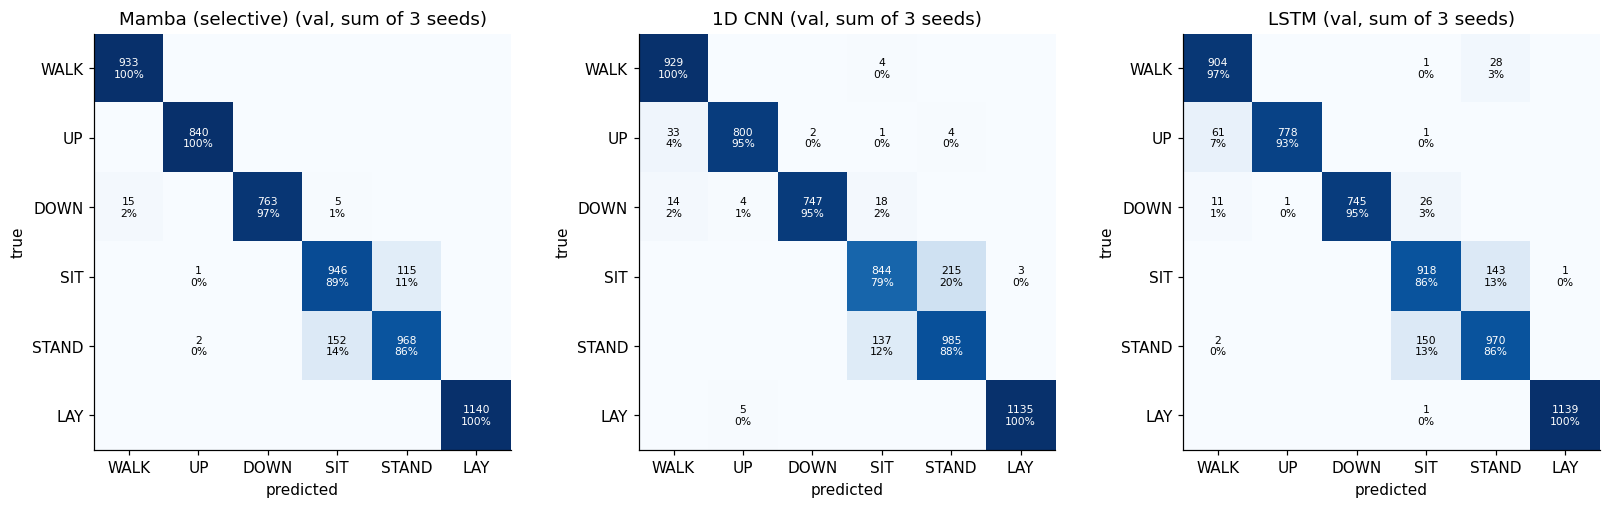

In [4]:
cms = {m: np.array([r["confusion_matrix"] for r in summ[m]["runs"]]) for m in MODELS}   # [3 seeds, 6, 6]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, m in zip(axes, MODELS):
    cm = cms[m].sum(0); cmn = cm / cm.sum(1, keepdims=True)                          # 3 seeds 합산 → 행 정규화
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1); ax.grid(False)
    for i in range(6):
        for j in range(6):
            if cm[i, j]: ax.text(j, i, f"{cm[i, j]}\n{cmn[i, j]:.0%}", ha="center", va="center",
                                 color="w" if cmn[i, j] > .5 else "k", fontsize=7)
    ax.set(xticks=range(6), yticks=range(6), xlabel="predicted", ylabel="true", title=f"{MODELS[m]} (val, sum of 3 seeds)")
    ax.set_xticklabels(SHORT); ax.set_yticklabels(SHORT)
fig.tight_layout(); fig.savefig(FIG / "t1_4_confusion.png", bbox_inches="tight"); plt.show()

In [5]:
def per_class_f1(cm):
    tp = np.diag(cm); return 2 * tp / np.maximum(cm.sum(0) + cm.sum(1), 1)

rows = []
for m, name in MODELS.items():
    f1 = np.stack([per_class_f1(c) for c in cms[m]])                                # seed별 클래스 F1 [3, 6]
    cm = cms[m].sum(0); err = cm.sum() - np.trace(cm)
    rows.append({"model": name, **{k: f"{f1[:, i].mean():.3f} ± {f1[:, i].std(ddof=1):.3f}" for i, k in enumerate(SHORT)},
                 "errors": err, "SIT↔STAND share": (cm[3, 4] + cm[4, 3]) / err,
                 "within-walking err": (cm[:3, :3].sum() - np.trace(cm[:3, :3])) / cm[:3].sum()})
class_table = pd.DataFrame(rows).set_index("model")
RESULTS["task1_4_per_class"] = class_table.to_dict("index")
class_table.style.format({"SIT↔STAND share": "{:.1%}", "within-walking err": "{:.2%}"})

,WALK,UP,DOWN,SIT,STAND,LAY,errors,SIT↔STAND share,within-walking err
model,,,,,,,,,
Mamba (selective),0.992 ± 0.010,0.998 ± 0.000,0.987 ± 0.016,0.874 ± 0.013,0.878 ± 0.012,1.000 ± 0.000,290,92.1%,0.59%
1D CNN,0.973 ± 0.016,0.970 ± 0.016,0.975 ± 0.016,0.816 ± 0.034,0.847 ± 0.012,0.996 ± 0.002,440,80.0%,2.07%
LSTM,0.946 ± 0.036,0.960 ± 0.032,0.975 ± 0.011,0.848 ± 0.044,0.858 ± 0.021,0.999 ± 0.002,426,68.8%,2.86%


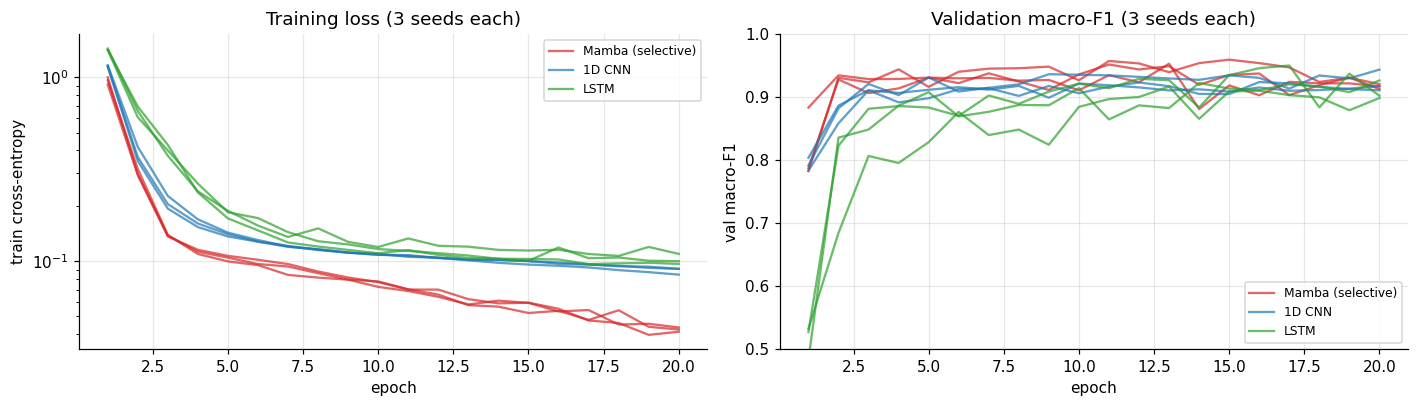

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for m in MODELS:
    for seed in (0, 1, 2):
        h = json.loads((RUNS / f"har_{m}" / f"seed_{seed}" / "history.json").read_text())
        ep, lab = [e["epoch"] for e in h], (MODELS[m] if seed == 0 else None)
        axes[0].plot(ep, [e["train_loss"] for e in h], color=MODEL_COLORS[m], alpha=.7, label=lab)
        axes[1].plot(ep, [e["macro_f1"] for e in h], color=MODEL_COLORS[m], alpha=.7, label=lab)
axes[0].set(xlabel="epoch", ylabel="train cross-entropy", yscale="log", title="Training loss (3 seeds each)")
axes[1].set(xlabel="epoch", ylabel="val macro-F1", title="Validation macro-F1 (3 seeds each)", ylim=(0.5, 1))
for ax in axes: ax.legend()
fig.tight_layout(); fig.savefig(FIG / "t1_4_curves.png", bbox_inches="tight"); plt.show()

**요약**
- Mamba가 세 seed 모두 baseline보다 높고 편차도 작다. 단, 파라미터 수(20.5k / 6.8k / 14.2k)가 달라 selectivity 효과로 볼 수 없음 → LTI 비교(Task 1.5)가 통제 비교.
- 오류 대부분이 SITTING ↔ STANDING(Mamba 오류의 92%): 둘 다 정지 자세라 body 신호 ≈ 0이고 중력 방향(DC)만 다르다(Task 1.1–1.3 sanity D). Baseline은 보행 3종(UP → WALK)에서도 추가로 틀린다.
- Mamba의 val macro-F1은 3 epoch 이후 0.90–0.96에서 진동 → validation으로 epoch을 고른 값이라 약간 낙관적.

## Task 1.5 · Dissecting the Mamba block (shape trace)
학습된 Mamba(seed 0 `best.pt`)에 validation window 1개 `[1, 128, 9]`를 넣고 첫 블록을 코드 순서대로 손으로 재계산 → 단계별 shape 기록, `block(x)`·`model(x)`와 일치 확인.
b=batch, l=128, d=d_model=32, h=E·d=64, n=d_state=16, r=dt_rank=2.

In [7]:
ck = torch.load(RUNS / "har_mamba" / "seed_0" / "best.pt", map_location="cpu", weights_only=False)
model = build_model(**ck["model_kwargs"]); model.load_state_dict(ck["model_state"]); model.eval()
norm = Standardizer.from_state(ck["normalizer"])                                # train subjects에서 fit된 정규화
x_in = torch.as_tensor(norm.transform(x_all[va][:1]))

SRC = {"mamba_block.py": inspect.getsource(mamba_block).splitlines(), "models.py": inspect.getsource(models).splitlines()}
def at(fname, snippet):                                                         # snippet이 있는 첫 줄 번호
    return f"{fname}:{next(i + 1 for i, s in enumerate(SRC[fname]) if snippet in s)}"

trace = []
def rec(step, section, where, t):
    trace.append({"step": step, "Section 2.2": section, "code": where, "shape": tuple(t.shape)}); return t

blk = model.layers[0].mixer
with torch.no_grad():
    mask = torch.ones(x_in.shape[:2], dtype=torch.bool)
    x = rec("input window", "-", "batch", x_in)
    x = rec("input_proj (9 → d)", "Stacking: input projection", at("models.py", "self.input_proj(zero_pad"), model.input_proj(x))
    xn = rec("RMSNorm", "Stacking: RMSNorm", at("models.py", "x + self.mixer(self.norm(x)"), model.layers[0].norm(x))
    uz = rec("in_proj (d → 2h)", "Expand and split", at("mamba_block.py", "self.in_proj(x).chunk"), blk.in_proj(xn))
    u, z = uz.chunk(2, dim=-1)
    rec("u (main) / z (gate)", "Expand and split", at("mamba_block.py", "self.in_proj(x).chunk"), u)
    uc = rec("depthwise conv1d (k=4, pad=3)", "Short causal convolution", at("mamba_block.py", "u = self.conv1d("), blk.conv1d(u.transpose(1, 2)))
    uc = rec("crop first l (causal)", "Short causal convolution", at("mamba_block.py", "u = self.conv1d("), uc[:, :, :x.shape[1]].transpose(1, 2))
    uc = rec("SiLU", "Short causal convolution", at("mamba_block.py", "u = zero_pad(F.silu(u)"), F.silu(uc))
    xdbl = rec("x_proj (h → r+2n)", "Input-dependent parameters", at("mamba_block.py", "self.x_proj(u).split"), blk.x_proj(uc))
    raw_dt, B, C = xdbl.split([blk.dt_rank, blk.d_state, blk.d_state], -1)
    rec("raw_dt (low-rank)", "Input-dependent parameters", at("mamba_block.py", "self.x_proj(u).split"), raw_dt)
    rec("B_t, C_t (channel 공유)", "Input-dependent parameters", at("mamba_block.py", "self.x_proj(u).split"), B)
    delta = rec("Δ_t = softplus(dt_proj) (r → h)", "Input-dependent parameters", at("mamba_block.py", "F.softplus(self.dt_proj"), F.softplus(blk.dt_proj(raw_dt)))
    delta = delta * blk.delta_scale * mask[..., None]                           # hook: scale=1, dt_mult=None
    A = rec("A = -exp(A_log) (입력 무관)", "Selective SSM", at("mamba_block.py", "return -self.A_log.exp()"), blk.A)
    state = uc.new_zeros(1, blk.d_inner, blk.d_state); ys = []
    for t in range(x.shape[1]):
        dt = delta[:, t, :, None]
        a_t = (dt * A).exp()
        state = a_t * state + dt * B[:, t, None, :] * uc[:, t, :, None]
        ys.append((state * C[:, t, None, :]).sum(-1) + blk.D * uc[:, t])
        if t == 0:
            rec("a_t = exp(Δ_t·A)  (per step)", "Selective SSM", at("mamba_block.py", "candidate = (dt * A).exp()"), a_t)
            rec("h_t  (per step)", "Selective SSM", at("mamba_block.py", "candidate = (dt * A).exp()"), state)
            rec("y_t = Σ_n C_t h_t + D u_t  (per step)", "Selective SSM", at("mamba_block.py", "y = (state * C"), ys[-1])
    y = rec("stack over time", "Selective SSM", at("mamba_block.py", "return torch.stack(outputs"), torch.stack(ys, 1))
    out = rec("y ⊙ SiLU(z) → out_proj (h → d)", "Gating and output", at("mamba_block.py", "self.out_proj(y * F.silu(z))"), blk.out_proj(y * F.silu(z)))
    err_blk = float((out - blk(xn)).abs().max())
    x = rec("residual add", "Stacking: residual", at("models.py", "x + self.mixer(self.norm(x)"), x + out)
    x = rec("layer 2", "Stacking", at("models.py", "x = layer(x, dt_mult"), model.layers[1](x, mask=mask))
    x = rec("final RMSNorm → mean pool", "Stacking: classification", at("models.py", "self.head(masked_mean"), model.norm_f(x).mean(1))
    logits = rec("head → logits", "Stacking: classification", at("models.py", "self.head(masked_mean"), model.head(x))
    err_log = float((logits - model(x_in)).abs().max())
assert err_blk < 1e-5 and err_log < 1e-5
print(f"hand trace vs block(x): max|err| = {err_blk:.1e},  vs model(x): {err_log:.1e}")
RESULTS["task1_5_shape_trace"] = [{**r, "shape": list(r["shape"])} for r in trace]
pd.DataFrame(trace)

hand trace vs block(x): max|err| = 0.0e+00,  vs model(x): 0.0e+00


,step,Section 2.2,code,shape
0,input window,-,batch,"(1, 128, 9)"
1,input_proj (9 → d),Stacking: input projection,models.py:49,"(1, 128, 32)"
2,RMSNorm,Stacking: RMSNorm,models.py:20,"(1, 128, 32)"
3,in_proj (d → 2h),Expand and split,mamba_block.py:190,"(1, 128, 128)"
4,u (main) / z (gate),Expand and split,mamba_block.py:190,"(1, 128, 64)"
5,"depthwise conv1d (k=4, pad=3)",Short causal convolution,mamba_block.py:191,"(1, 64, 131)"
6,crop first l (causal),Short causal convolution,mamba_block.py:191,"(1, 128, 64)"
7,SiLU,Short causal convolution,mamba_block.py:192,"(1, 128, 64)"
8,x_proj (h → r+2n),Input-dependent parameters,mamba_block.py:161,"(1, 128, 34)"
9,raw_dt (low-rank),Input-dependent parameters,mamba_block.py:161,"(1, 128, 2)"


In [8]:
# forward() / ssm()의 모든 코드 줄 → Section 2.2 단계 (주석·docstring·빈 줄 제외; 위에서부터 처음 맞는 규칙)
RULES = [("def ", "-"), ("valid_mask(", "보조: 입력 검사"), ("zero_pad(F.silu(u)", "Short causal convolution"),
         ("zero_pad(self.out_proj", "Gating and output"), ("zero_pad(", "보조: padding → 0"),
         ("self.in_proj(x).chunk", "Expand and split"), ("self.conv1d(", "Short causal convolution"),
         ("self.ssm(", "Selective SSM"), ("raise ValueError", "보조: 입력 검사"), ("self.d_inner:", "보조: 입력 검사"),
         ("b, l, h = u.shape", "보조"), ("if self.selective", "Input-dependent parameters"),
         ("self.x_proj(u).split", "Input-dependent parameters"), ("F.softplus(self.dt_proj", "Input-dependent parameters"),
         ("else:", "(LTI 변형: 상수 Δ, B, C)"), ("_const", "(LTI 변형: 상수 Δ, B, C)"), ("self.dt_bias", "(LTI 변형: 상수 Δ, B, C)"),
         ("self.delta_scale", "Input-dependent parameters (+ Δ hook)"), ("A = self.A", "Selective SSM"),
         ("new_zeros", "Selective SSM"), ("outputs, states", "보조"), ("for t in range", "Selective SSM"),
         ("dt = delta[", "Selective SSM"), ("candidate =", "Selective SSM"), ("torch.where(mask", "Selective SSM (+ padding)"),
         ("y = (state * C", "Selective SSM"), ("outputs.append", "Selective SSM (+ padding)"),
         ("record", "보조: 기록 hook"), ("states", "보조: 기록 hook"), ('"delta"', "보조: 기록 hook"),
         ("return torch.stack(outputs", "Selective SSM")]
rows = []
for fn in (mamba_block.MambaBlock.forward, mamba_block.MambaBlock.ssm):
    lines, start = inspect.getsourcelines(fn); in_doc = False
    for i, raw in enumerate(lines):
        st = raw.strip()
        if st.startswith('\"\"\"'):
            in_doc = (not in_doc) and st.count('\"\"\"') == 1; continue
        if in_doc or not st or st.startswith("#"):
            continue
        rows.append({"line": start + i, "code": st.split("  #")[0].strip()[:80],
                     "Section 2.2": next((s_ for k, s_ in RULES if k in st), "?")})
line_map = pd.DataFrame(rows)
assert (line_map["Section 2.2"] != "?").all()
RESULTS["task1_5_line_map"] = line_map.to_dict("records")
line_map.style.hide(axis="index").set_properties(**{"text-align": "left"})

line,code,Section 2.2
187,"def forward(self, x, dt_mult=None, mask=None):",-
188,"mask = valid_mask(x, mask)",보조: 입력 검사
189,"x = zero_pad(x, mask)",보조: padding → 0
190,"u, z = self.in_proj(x).chunk(2, dim=-1)",Expand and split
191,"u = self.conv1d(u.transpose(1, 2))[:, :, :x.shape[1]].transpose(1, 2)",Short causal convolution
192,"u = zero_pad(F.silu(u), mask)",Short causal convolution
193,"y = self.ssm(u, dt_mult=dt_mult, mask=mask)",Selective SSM
194,"return zero_pad(self.out_proj(y * F.silu(z)), mask)",Gating and output
148,"def ssm(self, u, dt_mult=None, mask=None):",-
155,"mask = valid_mask(u, mask)",보조: 입력 검사


In [9]:
# layer 0 파라미터: 입력 의존(x_proj, dt_proj) vs 입력 무관(A_log, D, conv, in/out_proj)
params = pd.DataFrame([{"parameter": k, "shape": tuple(v.shape), "#params": v.numel()} for k, v in blk.named_parameters()])
print(f"MambaBlock: {params['#params'].sum()} params / classifier: {sum(v.numel() for v in model.parameters())} params")
params

MambaBlock: 9920 params / classifier: 20454 params


,parameter,shape,#params
0,A_log,"(64, 16)",1024
1,D,"(64,)",64
2,in_proj.weight,"(128, 32)",4096
3,conv1d.weight,"(64, 1, 4)",256
4,conv1d.bias,"(64,)",64
5,x_proj.weight,"(34, 64)",2176
6,dt_proj.weight,"(64, 2)",128
7,dt_proj.bias,"(64,)",64
8,out_proj.weight,"(32, 64)",2048


**요약** — Δ_t `[b,l,h]`는 채널·시간마다, B_t/C_t `[b,l,n]`은 시간마다 다르고(채널 공유), A `[h,n]`는 입력과 무관. 감쇠 a_t = exp(Δ_t·A)는 `[b,h,n]`이라 한 채널 안의 16개 state가 서로 다른 시간 스케일(EMA 필터 뱅크)을 가진다 → 기억 길이는 Δ 단독이 아니라 Δ·A가 결정.

## Sanity checks (분석이 맞게 돌았는지 확인)
(A) 저장된 checkpoint를 다시 불러 평가하면 `summary.json`의 validation 지표가 재현되는지 (B) split이 Task 1.1–1.3 노트북(`subject_split`, seed 42)과 같은지.

In [10]:
# (A) 9개 checkpoint 재평가 → summary.json과 비교
rows = []
for m in MODELS:
    for r in summ[m]["runs"]:
        c = torch.load(RUNS / f"har_{m}" / f"seed_{r['seed']}" / "best.pt", map_location="cpu", weights_only=False)
        net = build_model(**c["model_kwargs"]); net.load_state_dict(c["model_state"])
        xv = Standardizer.from_state(c["normalizer"]).transform(x_all[va])
        ev = evaluate_model(net, make_loader(xv, y_all[va], c["config"], validation=True), torch.device("cpu"), 6)
        rows.append({"model": MODELS[m], "seed": r["seed"], "summary_F1": r["macro_f1"], "reloaded_F1": ev["macro_f1"],
                     "match": np.isclose(ev["macro_f1"], r["macro_f1"]) and ev["confusion_matrix"] == r["confusion_matrix"]})
reload_df = pd.DataFrame(rows)
RESULTS["sanity_A"] = reload_df.round(5).to_dict("records")
reload_df.round(4)

,model,seed,summary_F1,reloaded_F1,match
0,Mamba (selective),0,0.9531,0.9531,True
1,Mamba (selective),1,0.9519,0.9519,True
2,Mamba (selective),2,0.9595,0.9595,True
3,1D CNN,0,0.9437,0.9437,True
4,1D CNN,1,0.9217,0.9217,True
5,1D CNN,2,0.9240,0.9240,True
6,LSTM,0,0.9265,0.9265,True
7,LSTM,1,0.9168,0.9168,True
8,LSTM,2,0.9502,0.9502,True


In [11]:
# (B) Task 1.1–1.3과 같은 분할인지
chk_b = {"val_subjects": np.unique(subj_all[va]).tolist(), "same_as_runs": np.unique(subj_all[va]).tolist() == split["mamba"]["val_subjects"],
         "same_indices": va.tolist() == split["mamba"]["val_indices"] and tr.tolist() == split["mamba"]["train_indices"]}
RESULTS["sanity_B"] = chk_b; chk_b

{'val_subjects': [17, 21, 25, 26, 30],
 'same_as_runs': True,
 'same_indices': True}

In [12]:
(ROOT / "outputs").mkdir(exist_ok=True)
(ROOT / "outputs" / "phase1_B_results.json").write_text(json.dumps(RESULTS, indent=2, default=float, ensure_ascii=False))

22531